<h2>IS453 Financial Analytics</h2><h2>Group Assignment - Home Improvement Loan Scorecard</h2>

### Step 1: Flatten Bureau Data

This notebook follows `00_Customer_Segmentation.ipynb`. It turns the raw Bureau Data (many credit records per applicant) into **one row per applicant** with meaningful, non-redundant credit-risk characteristics.

Scope: no Application–Bureau merge, no use of `TARGET`, no WOE/IV and no modelling. Those come in later steps.

## 1.1 Business Context and Purpose

We are developing a credit scorecard for **Home Improvement Loans**. The Bureau Data describes each applicant's historical credit relationships with other lenders:

- number of historical credit accounts
- active and closed credit obligations
- outstanding debt and credit exposure
- current and historical overdue payments
- credit account ages and durations
- credit types and repayment commitments

Unlike the Application Data, the Bureau Data can contain **many records for one `SK_ID_CURR`** (one per reported credit). A scorecard needs exactly one row per applicant, so these records must be aggregated into applicant-level characteristics before merging.

The objective is **not simply to reduce the number of rows**. Each aggregation must keep the credit-risk meaning of the underlying records (e.g. *how much active debt*, *how severe the worst delinquency*, *how long the credit history*), while avoiding features that duplicate one another.

**Illustration (hypothetical values):** three bureau records for one applicant condensed into one row.

| SK_ID_CURR | SK_BUREAU_ID | CREDIT_ACTIVE | CREDIT_TYPE | DAYS_CREDIT | AMT_CREDIT_SUM_DEBT | CREDIT_DAY_OVERDUE |
|---|---|---|---|---|---|---|
| 100001 | 5001 | Active | Consumer credit | -400 | 50,000 | 0 |
| 100001 | 5002 | Active | Credit card | -1,200 | 20,000 | 15 |
| 100001 | 5003 | Closed | Car loan | -2,500 | 0 | 0 |

⬇ aggregated by `SK_ID_CURR`

| SK_ID_CURR | BUREAU_LOAN_COUNT | ACTIVE_LOAN_COUNT | TOTAL_ACTIVE_DEBT | MAX_DAYS_OVERDUE | OLDEST_CREDIT_AGE (yrs) | MOST_RECENT_CREDIT_AGE (yrs) |
|---|---|---|---|---|---|---|
| 100001 | 3 | 2 | 70,000 | 15 | 6.84 | 1.10 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# show more columns and format floats for readability
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:,.4f}'.format)

## 1.2 Load and Inspect Raw Bureau Data

Load the raw Bureau Data and the Step 0 segment. The segment file is only used to get the list of eligible applicant IDs; no application characteristics or `TARGET` are brought in.

In [2]:
# load raw bureau data and keep an untouched copy
bureau_path = 'data/raw/IS453 Group Assignment - Bureau Data.csv'
bureau_data = pd.read_csv(bureau_path)
bureau_data_orig = bureau_data.copy()

# load only the applicant IDs from the Step 0 segment
segment_ids = pd.read_csv('data/home_improvement_segment.csv', usecols=['SK_ID_CURR'])['SK_ID_CURR']

print('Original bureau data shape:', bureau_data_orig.shape)
print(f"Unique SK_ID_CURR in bureau data: {bureau_data_orig['SK_ID_CURR'].nunique():,}")
print(f"Unique SK_ID_BUREAU in bureau data: {bureau_data_orig['SK_ID_BUREAU'].nunique():,}")
print(f'Eligible applicants from Step 0: {len(segment_ids):,} (unique: {segment_ids.nunique():,})')

Original bureau data shape: (1716428, 17)
Unique SK_ID_CURR in bureau data: 305,811
Unique SK_ID_BUREAU in bureau data: 1,716,428
Eligible applicants from Step 0: 213,312 (unique: 213,312)


**Keep only bureau records of eligible applicants**

Use `.isin()` to filter rows rather than merging, so no application data is attached.

In [3]:
# retain bureau records whose SK_ID_CURR is in the Step 0 segment
bureau_seg = bureau_data_orig[bureau_data_orig['SK_ID_CURR'].isin(segment_ids)].copy()

print(f'Bureau rows for eligible applicants: {len(bureau_seg):,} of {len(bureau_data_orig):,}')
print(f"Eligible applicants WITH bureau records:    {bureau_seg['SK_ID_CURR'].nunique():,}")
print(f"Eligible applicants WITHOUT bureau records: {(~segment_ids.isin(bureau_seg['SK_ID_CURR'])).sum():,}")

Bureau rows for eligible applicants: 1,016,708 of 1,716,428
Eligible applicants WITH bureau records:    181,842
Eligible applicants WITHOUT bureau records: 31,470


In [4]:
# bureau records per applicant
records_per_app = bureau_seg.groupby('SK_ID_CURR').size()

print(f'Average records per applicant: {records_per_app.mean():.2f}')
print(f'Median records per applicant:  {records_per_app.median():.0f}')
print(f'Maximum records per applicant: {records_per_app.max():.0f}')

Average records per applicant: 5.59
Median records per applicant:  4
Maximum records per applicant: 94


**Column names, data types and missing values**

In [5]:
# data types and missing value percentages for every bureau column
column_summary = pd.DataFrame({
    'Data type': bureau_seg.dtypes.astype(str),
    'Non-null count': bureau_seg.notnull().sum(),
    'Missing %': bureau_seg.isnull().mean() * 100
})
column_summary

,Data type,Non-null count,Missing %
SK_ID_CURR,int64,1016708,0.0000
SK_ID_BUREAU,int64,1016708,0.0000
CREDIT_ACTIVE,object,1016708,0.0000
CREDIT_CURRENCY,object,1016708,0.0000
DAYS_CREDIT,int64,1016708,0.0000
CREDIT_DAY_OVERDUE,int64,1016708,0.0000
DAYS_CREDIT_ENDDATE,float64,955745,5.9961
DAYS_ENDDATE_FACT,float64,641112,36.9424
AMT_CREDIT_MAX_OVERDUE,float64,356716,64.9146
CNT_CREDIT_PROLONG,int64,1016708,0.0000


`AMT_ANNUITY` (77% missing), `AMT_CREDIT_MAX_OVERDUE` (65%), `DAYS_ENDDATE_FACT` (37%), `AMT_CREDIT_SUM_LIMIT` (34%) and `AMT_CREDIT_SUM_DEBT` (15%) have notable gaps. `DAYS_ENDDATE_FACT` is defined only for closed credit, so its missingness is largely structural. Missing values are **not** replaced with zero before aggregation.

**Categorical characteristics**

In [6]:
# unique category values for the categorical bureau variables
for col in ['CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'CREDIT_TYPE']:
    counts = bureau_seg[col].value_counts(dropna=False).to_frame('Count')
    counts['Percent (%)'] = counts['Count'] / len(bureau_seg) * 100
    display(counts)

,Count,Percent (%)
CREDIT_ACTIVE,,
Closed,639114,62.8611
Active,373688,36.7547
Sold,3894,0.3830
Bad debt,12,0.0012


,Count,Percent (%)
CREDIT_CURRENCY,,
currency 1,1015884,99.9190
currency 2,721,0.0709
currency 3,97,0.0095
currency 4,6,0.0006


,Count,Percent (%)
CREDIT_TYPE,,
Consumer credit,745094,73.2850
Credit card,235353,23.1485
Car loan,16038,1.5774
Mortgage,11247,1.1062
Microloan,6510,0.6403
Loan for business development,1217,0.1197
Another type of loan,558,0.0549
Unknown type of loan,358,0.0352
Loan for working capital replenishment,283,0.0278


- `CREDIT_ACTIVE` has four statuses. Besides *Active* and *Closed* there are *Sold* and *Bad debt* records, which are adverse outcomes (debt sold to a collector or written off). They are not silently treated as active or closed.
- `CREDIT_CURRENCY` is almost entirely *currency 1*. The currencies are recoded and no exchange rates are provided, so amounts in different currencies are **not comparable**.
- `CREDIT_TYPE` is dominated by *Consumer credit* and *Credit card*; many types are very rare.

In [7]:
# cross-tab of credit type by status, to see which products are active
pd.crosstab(bureau_seg['CREDIT_TYPE'], bureau_seg['CREDIT_ACTIVE'], margins=True)

CREDIT_ACTIVE,Active,Bad debt,Closed,Sold,All
CREDIT_TYPE,,,,,
Another type of loan,92,0,455,11,558
Car loan,5718,0,10046,274,16038
Cash loan (non-earmarked),13,0,1,1,15
Consumer credit,189754,9,553445,1886,745094
Credit card,168205,3,65829,1316,235353
Loan for business development,219,0,995,3,1217
Loan for purchase of shares (margin lending),2,0,1,0,3
Loan for the purchase of equipment,1,0,13,0,14
Loan for working capital replenishment,144,0,129,10,283


**Numerical distributions and suspicious values**

In [8]:
# summary statistics for numeric bureau variables
numeric_cols = ['DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT',
                'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT',
                'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'DAYS_CREDIT_UPDATE', 'AMT_ANNUITY']

bureau_seg[numeric_cols].describe(percentiles=[0.01, 0.5, 0.99]).T

,count,mean,std,min,1%,50%,99%,max
DAYS_CREDIT,"1,016,708.0000","-1,144.5847",801.4585,"-2,922.0000","-2,869.0000",-986.0000,-37.0000,0.0000
CREDIT_DAY_OVERDUE,"1,016,708.0000",0.9046,38.5962,0.0000,0.0000,0.0000,0.0000,"2,792.0000"
DAYS_CREDIT_ENDDATE,"955,745.0000",475.9178,"4,940.6029","-42,060.0000","-2,572.0000",-340.0000,"31,060.0000","31,199.0000"
DAYS_ENDDATE_FACT,"641,112.0000","-1,023.8035",718.8181,"-42,023.0000","-2,640.0000",-902.0000,-24.0000,0.0000
AMT_CREDIT_MAX_OVERDUE,"356,716.0000","3,823.8522","206,114.1526",0.0000,0.0000,0.0000,"41,266.9890","115,987,185.0000"
CNT_CREDIT_PROLONG,"1,016,708.0000",0.0071,0.1009,0.0000,0.0000,0.0000,0.0000,8.0000
AMT_CREDIT_SUM,"1,016,705.0000","350,203.9276","1,106,490.6622",0.0000,0.0000,"123,214.5000","3,690,000.0000","396,000,000.0000"
AMT_CREDIT_SUM_DEBT,"860,042.0000","135,958.5003","650,688.9295","-4,705,600.3200",0.0000,0.0000,"2,281,011.6150","64,570,243.5000"
AMT_CREDIT_SUM_LIMIT,"675,035.0000","6,277.1245","45,565.4767","-586,406.1150",0.0000,0.0000,"202,500.0000","4,705,600.3200"
AMT_CREDIT_SUM_OVERDUE,"1,016,708.0000",43.5418,"7,285.6371",0.0000,0.0000,0.0000,0.0000,"3,756,681.0000"


In [9]:
# check for suspicious values
suspicious = pd.DataFrame({
    'Negative values': [(bureau_seg[c] < 0).sum() for c in numeric_cols],
    'Positive values': [(bureau_seg[c] > 0).sum() for c in numeric_cols],
    'Zero values': [(bureau_seg[c] == 0).sum() for c in numeric_cols],
}, index=numeric_cols)
suspicious

,Negative values,Positive values,Zero values
DAYS_CREDIT,1016704,0,4
CREDIT_DAY_OVERDUE,0,2529,1014179
DAYS_CREDIT_ENDDATE,600912,354296,537
DAYS_ENDDATE_FACT,641063,0,49
AMT_CREDIT_MAX_OVERDUE,0,73025,283691
CNT_CREDIT_PROLONG,0,5929,1010779
AMT_CREDIT_SUM,0,978509,38196
AMT_CREDIT_SUM_DEBT,5660,254932,599450
AMT_CREDIT_SUM_LIMIT,239,44149,630647
AMT_CREDIT_SUM_OVERDUE,0,2479,1014229


In [10]:
# date checks relative to the application date (day 0) and the account open date
date_checks = pd.DataFrame({
    'Rule violated': [
        'DAYS_CREDIT > 0 (opened after application)',
        'DAYS_CREDIT_UPDATE > 0 (updated after application)',
        'DAYS_ENDDATE_FACT > 0 (closed after application)',
        'DAYS_CREDIT_ENDDATE < DAYS_CREDIT (end before opening)',
        'DAYS_ENDDATE_FACT < DAYS_CREDIT (closed before opening)',
        'DAYS_CREDIT_UPDATE < DAYS_CREDIT (updated before opening)',
    ],
    'Records': [
        (bureau_seg['DAYS_CREDIT'] > 0).sum(),
        (bureau_seg['DAYS_CREDIT_UPDATE'] > 0).sum(),
        (bureau_seg['DAYS_ENDDATE_FACT'] > 0).sum(),
        (bureau_seg['DAYS_CREDIT_ENDDATE'] < bureau_seg['DAYS_CREDIT']).sum(),
        (bureau_seg['DAYS_ENDDATE_FACT'] < bureau_seg['DAYS_CREDIT']).sum(),
        (bureau_seg['DAYS_CREDIT_UPDATE'] < bureau_seg['DAYS_CREDIT']).sum(),
    ]
})
date_checks

,Rule violated,Records
0,DAYS_CREDIT > 0 (opened after application),0
1,DAYS_CREDIT_UPDATE > 0 (updated after applicat...,11
2,DAYS_ENDDATE_FACT > 0 (closed after application),0
3,DAYS_CREDIT_ENDDATE < DAYS_CREDIT (end before ...,108
4,DAYS_ENDDATE_FACT < DAYS_CREDIT (closed before...,10
5,DAYS_CREDIT_UPDATE < DAYS_CREDIT (updated befo...,74


In [11]:
# negative monetary values by status
print('Negative AMT_CREDIT_SUM_DEBT by status:')
print(bureau_seg[bureau_seg['AMT_CREDIT_SUM_DEBT'] < 0]['CREDIT_ACTIVE'].value_counts())
print('\nNegative AMT_CREDIT_SUM_LIMIT by status:')
print(bureau_seg[bureau_seg['AMT_CREDIT_SUM_LIMIT'] < 0]['CREDIT_ACTIVE'].value_counts())

# which credit types report a positive credit limit
print('\nCredit types with AMT_CREDIT_SUM_LIMIT > 0:')
print(bureau_seg[bureau_seg['AMT_CREDIT_SUM_LIMIT'] > 0]['CREDIT_TYPE'].value_counts())

Negative AMT_CREDIT_SUM_DEBT by status:
CREDIT_ACTIVE
Active    4165
Closed    1495
Name: count, dtype: int64

Negative AMT_CREDIT_SUM_LIMIT by status:
CREDIT_ACTIVE
Active      208
Closed       27
Sold          3
Bad debt      1
Name: count, dtype: int64

Credit types with AMT_CREDIT_SUM_LIMIT > 0:
CREDIT_TYPE
Credit card        44128
Consumer credit       16
Car loan               5
Name: count, dtype: int64


**Duplicated or inconsistent bureau IDs**

In [12]:
# each SK_ID_BUREAU should appear once and belong to one applicant only
print('Duplicated SK_ID_BUREAU values:', bureau_data_orig['SK_ID_BUREAU'].duplicated().sum())
print('Fully duplicated rows:', bureau_data_orig.duplicated().sum())
print('Max applicants linked to one SK_ID_BUREAU:', bureau_data_orig.groupby('SK_ID_BUREAU')['SK_ID_CURR'].nunique().max())

Duplicated SK_ID_BUREAU values: 0
Fully duplicated rows: 0
Max applicants linked to one SK_ID_BUREAU: 1


**Inspection findings**

- Every `SK_ID_BUREAU` is unique and belongs to exactly one applicant, so `BUREAU_LOAN_COUNT` can be counted reliably.
- `DAYS_CREDIT` is always ≤ 0, so every credit was opened on or before the application date.
- A small number of records have `DAYS_CREDIT_UPDATE > 0`, meaning the bureau information was updated **after** the application. That information was not available at decision time.
- Some end/update dates fall **before** the account was opened, which is impossible.
- `AMT_CREDIT_SUM_DEBT` has negative values, consistent with an overpaid balance (the lender owes the client). `AMT_CREDIT_SUM_LIMIT` also has negative values, which make no sense for a credit limit.
- Positive credit limits are reported almost only for credit cards, so `AMT_CREDIT_SUM_LIMIT` is treated as a revolving-credit limit.

### Data-quality treatment

| Issue | Treatment | Reason |
|---|---|---|
| `DAYS_CREDIT_UPDATE > 0` | Exclude the record | Information not available as of the application date (avoids look-ahead leakage). |
| End/update date earlier than `DAYS_CREDIT` | Set that date field to missing; keep the record | The account itself is valid; only the date is impossible. |
| Negative `AMT_CREDIT_SUM_DEBT` | Set to 0 | An overpaid balance means nothing is currently owed; a negative value would offset genuine debt in sums. |
| Negative `AMT_CREDIT_SUM_LIMIT` | Set to missing | A negative limit is invalid and cannot be interpreted. |
| Non-`currency 1` amounts | Excluded from monetary sums only | No exchange rates are provided, so cross-currency sums would be misleading. Counts, days and statuses still use these records. |
| Missing numeric values | Left as missing | Missing does not mean zero (e.g. unreported debt is not zero debt). |

In [13]:
# start from a cleaned copy of the eligible bureau records
bureau_clean = bureau_seg.copy()

# exclude records updated after the application date
future_update = bureau_clean['DAYS_CREDIT_UPDATE'] > 0
apps_before = bureau_clean['SK_ID_CURR'].nunique()
bureau_clean = bureau_clean[~future_update].copy()
print(f'Records excluded (updated after application): {future_update.sum()}')
print(f"Applicants who lost all bureau records as a result: {apps_before - bureau_clean['SK_ID_CURR'].nunique()}")

# impossible dates: earlier than the account open date -> missing
for col in ['DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'DAYS_CREDIT_UPDATE']:
    invalid = bureau_clean[col] < bureau_clean['DAYS_CREDIT']
    bureau_clean.loc[invalid, col] = np.nan
    print(f'{col}: {invalid.sum()} impossible dates set to missing')

# negative debt -> 0 (overpaid), negative limit -> missing (invalid)
print('Negative debt set to 0:', (bureau_clean['AMT_CREDIT_SUM_DEBT'] < 0).sum())
bureau_clean.loc[bureau_clean['AMT_CREDIT_SUM_DEBT'] < 0, 'AMT_CREDIT_SUM_DEBT'] = 0
print('Negative limit set to missing:', (bureau_clean['AMT_CREDIT_SUM_LIMIT'] < 0).sum())
bureau_clean.loc[bureau_clean['AMT_CREDIT_SUM_LIMIT'] < 0, 'AMT_CREDIT_SUM_LIMIT'] = np.nan

# flag records whose amounts can be summed (currency 1 only)
non_c1 = bureau_clean['CREDIT_CURRENCY'] != 'currency 1'
print(f"\nNon-currency-1 records: {non_c1.sum()} across {bureau_clean.loc[non_c1, 'SK_ID_CURR'].nunique()} applicants (excluded from monetary sums)")
print('Clean bureau records:', bureau_clean.shape)

Records excluded (updated after application): 11
Applicants who lost all bureau records as a result: 1
DAYS_CREDIT_ENDDATE: 108 impossible dates set to missing
DAYS_ENDDATE_FACT: 10 impossible dates set to missing
DAYS_CREDIT_UPDATE: 74 impossible dates set to missing
Negative debt set to 0: 5660
Negative limit set to missing: 239

Non-currency-1 records: 824 across 640 applicants (excluded from monetary sums)
Clean bureau records: (1016697, 17)


## 1.3 Complete Bureau Variable Mapping

Every raw bureau column (all 17 dictionary variables, checked against the raw file below) is mapped to an aggregation or exclusion decision, using the data dictionary definitions and the inspection above.

In [14]:
# confirm every documented bureau variable exists in the raw file
data_dict = pd.read_excel('data/raw/IS453 Group Assignment - Data Dict.xlsx', sheet_name='Bureau Data')
dict_vars = data_dict.iloc[:, 0].tolist()

print('Variables in data dictionary:', len(dict_vars))
print('Missing from raw file:', [v for v in dict_vars if v not in bureau_data_orig.columns])
print('In raw file but not in dictionary:', [v for v in bureau_data_orig.columns if v not in dict_vars])

Variables in data dictionary: 17
Missing from raw file: ['SK_BUREAU_ID']
In raw file but not in dictionary: ['SK_ID_BUREAU']


The only mismatch is a naming difference: the data dictionary spells the bureau account ID as `SK_BUREAU_ID`, while the raw file uses `SK_ID_BUREAU`. They are the same variable, so all 17 dictionary variables are present.

| Original variable | Data dictionary meaning | Transformation | Engineered characteristic(s) | Business rationale / decision |
|---|---|---|---|---|
| `SK_ID_CURR` | ID of loan in our sample | Grouping key | `SK_ID_CURR` | Identifies the applicant; one row per value. |
| `SK_ID_BUREAU` (dictionary: `SK_BUREAU_ID`) | ID of previous bureau credit | Count unique | `BUREAU_LOAN_COUNT` | Number of recorded credit relationships. The ID itself is **dropped** from the output. |
| `CREDIT_ACTIVE` | Status of bureau credit | Count by category; ratio | `ACTIVE_LOAN_COUNT`, `CLOSED_LOAN_COUNT`, `ADVERSE_STATUS_COUNT`, `ACTIVE_LOAN_RATIO` | Existing vs completed obligations. *Sold* and *Bad debt* are combined into an adverse-status count (Bad debt alone is too rare to stand on its own) rather than being forced into active/closed. |
| `CREDIT_CURRENCY` | Recoded currency | Number of distinct values; used as a filter | `CREDIT_CURRENCY_COUNT` | Flags multi-currency histories. Also used to restrict monetary sums to currency 1. |
| `DAYS_CREDIT` | Days before application the credit was applied for (≤ 0) | `-min / 365.25`, `-max / 365.25` | `OLDEST_CREDIT_AGE`, `MOST_RECENT_CREDIT_AGE` (years) | Length and recency of credit history. |
| `CREDIT_DAY_OVERDUE` | Days past due at application | Max; count > 0; share | `MAX_DAYS_OVERDUE`, `OVERDUE_LOAN_COUNT`, `OVERDUE_LOAN_RATIO` | Current delinquency severity and frequency. Days are not currency-dependent, so all records are used. |
| `DAYS_CREDIT_ENDDATE` | Remaining duration of credit (signed) | Max over **active** records / 365.25 (sign kept) | `MAX_REMAINING_DURATION` (years) | Longest remaining commitment. Positive = years still to run; negative = active account past its scheduled end. |
| `DAYS_ENDDATE_FACT` | Days since credit ended (closed only) | `-max` over **closed** records / 365.25 | `LAST_CREDIT_END_AGE` (years) | How recently the applicant finished repaying a credit. |
| `AMT_CREDIT_MAX_OVERDUE` | Maximal amount overdue so far | Max (currency 1) | `MAX_HIST_OVERDUE` | Worst historical overdue amount, kept separate from current overdue. |
| `CNT_CREDIT_PROLONG` | Times credit was prolonged | Sum | `TOTAL_PROLONGATIONS` | Number of extensions requested, a possible sign of repayment strain. |
| `AMT_CREDIT_SUM` | Current credit amount | Sum over **active**, currency 1 | `TOTAL_ACTIVE_CREDIT` | Total active credit exposure. |
| `AMT_CREDIT_SUM_DEBT` | Current debt | Sum and max over **active**, currency 1; ratio to credit | `TOTAL_ACTIVE_DEBT`, `MAX_ACTIVE_DEBT`, `DEBT_TO_CREDIT_RATIO` | Outstanding liabilities. Closed-account balances are excluded. |
| `AMT_CREDIT_SUM_LIMIT` | Current credit limit of credit card | Sum over **active credit cards**, currency 1 | `TOTAL_REVOLVING_LIMIT` | Revolving credit available. The dictionary defines it for credit cards only. |
| `AMT_CREDIT_SUM_OVERDUE` | Current amount overdue | Sum (currency 1) | `TOTAL_OVERDUE_AMOUNT` | Amount currently overdue (current, not historical). |
| `CREDIT_TYPE` | Type of bureau credit | Count distinct; counts of major types; rare types grouped to OTHER | `CREDIT_TYPE_DIVERSITY`, `ACTIVE_CONSUMER_CREDIT_COUNT`, `ACTIVE_CREDIT_CARD_COUNT`, `MORTGAGE_COUNT`, `CAR_LOAN_COUNT`, `MICROLOAN_COUNT`, `OTHER_TYPE_COUNT` | Composition of borrowing. Types with < 0.5% of records are grouped into OTHER to avoid sparse columns. |
| `DAYS_CREDIT_UPDATE` | Days before application of last bureau update | `-max / 365.25`, `-min / 365.25` | `LATEST_BUREAU_UPDATE_AGE`, `OLDEST_BUREAU_UPDATE_AGE` (years) | Freshness/staleness of bureau information. |
| `AMT_ANNUITY` | Annuity of bureau credit | Sum over **active**, currency 1 | `TOTAL_ACTIVE_ANNUITY` | Existing periodic repayment burden, but the raw field is heavily missing. |

In [15]:
# credit types and the < 0.5% grouping rule
type_share = bureau_clean['CREDIT_TYPE'].value_counts(normalize=True) * 100
major_types = type_share[type_share >= 0.5].index.tolist()

print('Credit types kept individually (>= 0.5% of records):', major_types)
print('\nCredit types grouped into OTHER:')
print(type_share[type_share < 0.5].round(3))

Credit types kept individually (>= 0.5% of records): ['Consumer credit', 'Credit card', 'Car loan', 'Mortgage', 'Microloan']

Credit types grouped into OTHER:
CREDIT_TYPE
Loan for business development                  0.1200
Another type of loan                           0.0550
Unknown type of loan                           0.0350
Loan for working capital replenishment         0.0280
Real estate loan                               0.0020
Cash loan (non-earmarked)                      0.0010
Loan for the purchase of equipment             0.0010
Loan for purchase of shares (margin lending)   0.0000
Mobile operator loan                           0.0000
Name: proportion, dtype: float64


## 1.4 Engineer Bureau Characteristics

Characteristics are built group by group from the cleaned records. Rules applied throughout:

- Monetary sums use **currency 1 records only**.
- "Active" amounts use **Active** status only (Sold accounts are no longer with the original lender, and closed balances are history, not exposure).
- When an applicant has bureau history but **no active currency-1 account**, active-exposure amounts are a genuine 0 (nothing currently owed). This is a structural zero, not an imputed missing value. If an applicant does have active accounts but the amount was never reported, the result stays **missing** (`sum(min_count=1)`).
- Characteristics that are not applicable (e.g. remaining duration with no active accounts) stay missing.

In [16]:
# helper groupings used in several features
bureau_clean['TYPE_GROUP'] = bureau_clean['CREDIT_TYPE'].where(bureau_clean['CREDIT_TYPE'].isin(major_types), 'Other')

all_grp = bureau_clean.groupby('SK_ID_CURR')
active = bureau_clean[bureau_clean['CREDIT_ACTIVE'] == 'Active']
closed = bureau_clean[bureau_clean['CREDIT_ACTIVE'] == 'Closed']
c1 = bureau_clean[bureau_clean['CREDIT_CURRENCY'] == 'currency 1']
active_c1 = c1[c1['CREDIT_ACTIVE'] == 'Active']

# one row per applicant with bureau history
bureau_features = pd.DataFrame(index=all_grp.size().index)

### Group A — Credit Account History

In [17]:
# account counts by status
status_counts = pd.crosstab(bureau_clean['SK_ID_CURR'], bureau_clean['CREDIT_ACTIVE'])

bureau_features['BUREAU_LOAN_COUNT'] = all_grp['SK_ID_BUREAU'].nunique()
bureau_features['ACTIVE_LOAN_COUNT'] = status_counts['Active']
bureau_features['CLOSED_LOAN_COUNT'] = status_counts['Closed']
bureau_features['ADVERSE_STATUS_COUNT'] = status_counts['Sold'] + status_counts['Bad debt']

# share of accounts still active (denominator is always >= 1 for applicants with bureau records)
bureau_features['ACTIVE_LOAN_RATIO'] = bureau_features['ACTIVE_LOAN_COUNT'] / bureau_features['BUREAU_LOAN_COUNT'].replace(0, np.nan)

# number of different credit types and currencies
bureau_features['CREDIT_TYPE_DIVERSITY'] = all_grp['CREDIT_TYPE'].nunique()
bureau_features['CREDIT_CURRENCY_COUNT'] = all_grp['CREDIT_CURRENCY'].nunique()

bureau_features.iloc[:, -7:].describe().T

,count,mean,std,min,25%,50%,75%,max
BUREAU_LOAN_COUNT,"181,841.0000",5.5911,4.4138,1.0000,2.0000,4.0000,8.0000,94.0000
ACTIVE_LOAN_COUNT,"181,841.0000",2.0550,1.7964,0.0000,1.0000,2.0000,3.0000,32.0000
CLOSED_LOAN_COUNT,"181,841.0000",3.5147,3.4133,0.0000,1.0000,3.0000,5.0000,84.0000
ADVERSE_STATUS_COUNT,"181,841.0000",0.0215,0.1585,0.0000,0.0000,0.0000,0.0000,9.0000
ACTIVE_LOAN_RATIO,"181,841.0000",0.4109,0.3086,0.0000,0.2000,0.3750,0.6000,1.0000
CREDIT_TYPE_DIVERSITY,"181,841.0000",1.7411,0.6432,1.0000,1.0000,2.0000,2.0000,6.0000
CREDIT_CURRENCY_COUNT,"181,841.0000",1.0035,0.0601,1.0000,1.0000,1.0000,1.0000,3.0000


### Group B — Outstanding Debt Exposure

In [18]:
# applicants with at least one active currency-1 account
has_active_c1 = bureau_features.index.isin(active_c1['SK_ID_CURR'])
active_c1_grp = active_c1.groupby('SK_ID_CURR')

def active_amount(col, how='sum'):
    # aggregate an amount over active currency-1 accounts
    if how == 'sum':
        values = active_c1_grp[col].sum(min_count=1)
    else:
        values = active_c1_grp[col].max()
    values = values.reindex(bureau_features.index)
    # no active account means nothing currently owed: structural zero
    values[~has_active_c1] = 0
    return values

bureau_features['TOTAL_ACTIVE_DEBT'] = active_amount('AMT_CREDIT_SUM_DEBT')
bureau_features['MAX_ACTIVE_DEBT'] = active_amount('AMT_CREDIT_SUM_DEBT', how='max')
bureau_features['TOTAL_ACTIVE_CREDIT'] = active_amount('AMT_CREDIT_SUM')
bureau_features['TOTAL_ACTIVE_ANNUITY'] = active_amount('AMT_ANNUITY')

# debt-to-credit ratio: share of active credit still owed (undefined when there is no active credit)
bureau_features['DEBT_TO_CREDIT_RATIO'] = bureau_features['TOTAL_ACTIVE_DEBT'] / bureau_features['TOTAL_ACTIVE_CREDIT'].replace(0, np.nan)

# revolving limit: active credit cards only, as defined in the data dictionary
active_cards = active_c1[active_c1['CREDIT_TYPE'] == 'Credit card']
revolving_limit = active_cards.groupby('SK_ID_CURR')['AMT_CREDIT_SUM_LIMIT'].sum(min_count=1).reindex(bureau_features.index)
revolving_limit[~bureau_features.index.isin(active_cards['SK_ID_CURR'])] = 0
bureau_features['TOTAL_REVOLVING_LIMIT'] = revolving_limit

bureau_features.iloc[:, -6:].describe().T

,count,mean,std,min,25%,50%,75%,max
TOTAL_ACTIVE_DEBT,"174,539.0000","656,707.3537","1,503,879.7000",0.0000,0.0000,"182,432.3400","673,447.5000","74,487,294.0000"
MAX_ACTIVE_DEBT,"174,539.0000","523,388.9165","1,288,957.8949",0.0000,0.0000,"147,550.5000","489,901.5000","64,570,243.5000"
TOTAL_ACTIVE_CREDIT,"181,840.0000","1,075,496.8625","2,102,142.3367",0.0000,"82,701.6750","441,000.0000","1,256,332.5000","270,104,026.5000"
TOTAL_ACTIVE_ANNUITY,"74,722.0000","19,562.8786","233,611.5497",0.0000,0.0000,0.0000,"18,413.7637","56,844,981.0000"
DEBT_TO_CREDIT_RATIO,"140,153.0000",0.5582,1.0755,0.0000,0.2894,0.6097,0.8318,382.5100
TOTAL_REVOLVING_LIMIT,"166,929.0000","21,838.3444","93,990.7113",0.0000,0.0000,0.0000,0.0000,"6,978,830.4900"


In [19]:
# check the debt-to-credit ratio for values above 1 (debt larger than reported credit amount)
ratio = bureau_features['DEBT_TO_CREDIT_RATIO']
print(f'Applicants with DEBT_TO_CREDIT_RATIO > 1: {(ratio > 1).sum():,} ({(ratio > 1).sum() / ratio.notnull().sum():.2%} of non-missing)')

Applicants with DEBT_TO_CREDIT_RATIO > 1: 3,448 (2.46% of non-missing)


`DEBT_TO_CREDIT_RATIO` is a meaningful utilisation-style measure: both amounts come from the same active currency-1 accounts. Values above 1 (about 2.5% of non-missing) occur when reported debt exceeds the reported credit amount (e.g. accrued interest or a card balance above its reported amount). They are kept, not capped, and will be grouped by binning later.

### Group C — Delinquency and Repayment Behaviour

Severity (max days), frequency (count/share) and magnitude (amounts) are kept as separate characteristics, not collapsed into one score. Current overdue (`AMT_CREDIT_SUM_OVERDUE`) and historical maximum overdue (`AMT_CREDIT_MAX_OVERDUE`) are also kept separate.

In [20]:
# overdue flags per record
bureau_clean['IS_OVERDUE'] = (bureau_clean['CREDIT_DAY_OVERDUE'] > 0).astype(int)
all_grp = bureau_clean.groupby('SK_ID_CURR')
c1_grp = c1.groupby('SK_ID_CURR')

bureau_features['MAX_DAYS_OVERDUE'] = all_grp['CREDIT_DAY_OVERDUE'].max()
bureau_features['OVERDUE_LOAN_COUNT'] = all_grp['IS_OVERDUE'].sum()
bureau_features['OVERDUE_LOAN_RATIO'] = bureau_features['OVERDUE_LOAN_COUNT'] / bureau_features['BUREAU_LOAN_COUNT'].replace(0, np.nan)

# monetary overdue amounts: currency 1 only (missing if an applicant has no currency-1 records)
bureau_features['TOTAL_OVERDUE_AMOUNT'] = c1_grp['AMT_CREDIT_SUM_OVERDUE'].sum(min_count=1).reindex(bureau_features.index)
bureau_features['MAX_HIST_OVERDUE'] = c1_grp['AMT_CREDIT_MAX_OVERDUE'].max().reindex(bureau_features.index)

bureau_features['TOTAL_PROLONGATIONS'] = all_grp['CNT_CREDIT_PROLONG'].sum()

bureau_features.iloc[:, -6:].describe().T

,count,mean,std,min,25%,50%,75%,max
MAX_DAYS_OVERDUE,"181,841.0000",4.8618,90.0607,0.0000,0.0000,0.0000,0.0000,"2,792.0000"
OVERDUE_LOAN_COUNT,"181,841.0000",0.0139,0.1300,0.0000,0.0000,0.0000,0.0000,6.0000
OVERDUE_LOAN_RATIO,"181,841.0000",0.0030,0.0350,0.0000,0.0000,0.0000,0.0000,1.0000
TOTAL_OVERDUE_AMOUNT,"181,816.0000",243.4839,"19,122.7398",0.0000,0.0000,0.0000,0.0000,"3,756,681.0000"
MAX_HIST_OVERDUE,"126,655.0000","8,711.9164","340,811.6719",0.0000,0.0000,0.0000,"5,772.1275","115,987,185.0000"
TOTAL_PROLONGATIONS,"181,841.0000",0.0395,0.2438,0.0000,0.0000,0.0000,0.0000,8.0000


### Group D — Credit History and Recency

All `DAYS_*` variables are relative to the application date (day 0). Each is converted to years with a sign chosen so the result reads naturally:

- `OLDEST_CREDIT_AGE = -min(DAYS_CREDIT) / 365.25` → years since the first credit was opened
- `MOST_RECENT_CREDIT_AGE = -max(DAYS_CREDIT) / 365.25` → years since the latest credit was opened
- `MAX_REMAINING_DURATION = max(DAYS_CREDIT_ENDDATE of active records) / 365.25` → **sign kept**: positive means years left to run, negative means an active account past its scheduled end
- `LAST_CREDIT_END_AGE = -max(DAYS_ENDDATE_FACT of closed records) / 365.25` → years since the most recent closure
- `LATEST_BUREAU_UPDATE_AGE = -max(DAYS_CREDIT_UPDATE) / 365.25` → years since the freshest bureau update
- `OLDEST_BUREAU_UPDATE_AGE = -min(DAYS_CREDIT_UPDATE) / 365.25` → years since the stalest bureau update

In [21]:
bureau_features['OLDEST_CREDIT_AGE'] = -all_grp['DAYS_CREDIT'].min() / 365.25
bureau_features['MOST_RECENT_CREDIT_AGE'] = -all_grp['DAYS_CREDIT'].max() / 365.25

# remaining duration: active accounts only, sign kept
bureau_features['MAX_REMAINING_DURATION'] = (active.groupby('SK_ID_CURR')['DAYS_CREDIT_ENDDATE'].max() / 365.25).reindex(bureau_features.index)

# time since last closure: closed accounts only
bureau_features['LAST_CREDIT_END_AGE'] = (-closed.groupby('SK_ID_CURR')['DAYS_ENDDATE_FACT'].max() / 365.25).reindex(bureau_features.index)

bureau_features['LATEST_BUREAU_UPDATE_AGE'] = -all_grp['DAYS_CREDIT_UPDATE'].max() / 365.25
bureau_features['OLDEST_BUREAU_UPDATE_AGE'] = -all_grp['DAYS_CREDIT_UPDATE'].min() / 365.25

# -0.0 can appear from negating 0, tidy it to 0
for col in ['OLDEST_CREDIT_AGE', 'MOST_RECENT_CREDIT_AGE', 'LAST_CREDIT_END_AGE', 'LATEST_BUREAU_UPDATE_AGE', 'OLDEST_BUREAU_UPDATE_AGE']:
    bureau_features[col] = bureau_features[col] + 0.0

bureau_features.iloc[:, -6:].describe().T

,count,mean,std,min,25%,50%,75%,max
OLDEST_CREDIT_AGE,"181,841.0000",4.8434,2.3698,0.0000,2.8474,5.0513,7.0856,8.0000
MOST_RECENT_CREDIT_AGE,"181,841.0000",1.3361,1.4731,0.0000,0.3915,0.8159,1.6893,8.0000
MAX_REMAINING_DURATION,"143,461.0000",12.9635,25.6286,-7.6851,1.3388,2.8665,4.6817,85.4182
LAST_CREDIT_END_AGE,"158,949.0000",1.4466,1.4663,0.0000,0.4189,0.9473,1.9658,7.8960
LATEST_BUREAU_UPDATE_AGE,"181,839.0000",0.3892,0.9367,0.0000,0.0246,0.0493,0.1396,7.9671
OLDEST_BUREAU_UPDATE_AGE,"181,839.0000",3.2169,2.2683,0.0000,1.3169,2.9158,5.2512,7.9836


In [22]:
# check unusually long remaining durations
remaining = bureau_features['MAX_REMAINING_DURATION']
print(f'Applicants with MAX_REMAINING_DURATION > 10 years: {(remaining > 10).sum():,}')
print(f'Applicants with negative MAX_REMAINING_DURATION (active but past scheduled end): {(remaining < 0).sum():,}')

Applicants with MAX_REMAINING_DURATION > 10 years: 27,321
Applicants with negative MAX_REMAINING_DURATION (active but past scheduled end): 8,446


`MAX_REMAINING_DURATION` has a long right tail (some active accounts, mainly revolving products, report end dates decades away) and a group of active accounts past their scheduled end. Both are kept because they may carry risk information; binning in a later step will handle the extremes.

### Group E — Additional Characteristics

Added only where the distributions above justify them:

- **Active consumer credit and active credit card counts** – the two dominant products; instalment and revolving credit carry different risk.
- **Mortgage count** – directly relevant for homeowners seeking home improvement finance (existing housing debt).
- **Car loan count** and **microloan count** – each ≥ 0.5% of records; microloans are short-term, high-cost credit that can indicate financial stress.
- **OTHER type count** – all remaining rare types grouped per the 0.5% rule.
- **Overdue share** (`OVERDUE_LOAN_RATIO`) was created in Group C. Closure patterns are covered by `CLOSED_LOAN_COUNT`, `ACTIVE_LOAN_RATIO` and `LAST_CREDIT_END_AGE`, so no further closure feature is added.

In [23]:
# active product counts
active_types = pd.crosstab(active['SK_ID_CURR'], active['TYPE_GROUP']).reindex(bureau_features.index, fill_value=0)
bureau_features['ACTIVE_CONSUMER_CREDIT_COUNT'] = active_types['Consumer credit']
bureau_features['ACTIVE_CREDIT_CARD_COUNT'] = active_types['Credit card']

# product counts across all statuses
all_types = pd.crosstab(bureau_clean['SK_ID_CURR'], bureau_clean['TYPE_GROUP']).reindex(bureau_features.index, fill_value=0)
bureau_features['MORTGAGE_COUNT'] = all_types['Mortgage']
bureau_features['CAR_LOAN_COUNT'] = all_types['Car loan']
bureau_features['MICROLOAN_COUNT'] = all_types['Microloan']
bureau_features['OTHER_TYPE_COUNT'] = all_types['Other']

bureau_features.iloc[:, -6:].describe().T

,count,mean,std,min,25%,50%,75%,max
ACTIVE_CONSUMER_CREDIT_COUNT,"181,841.0000",1.0435,1.1373,0.0000,0.0000,1.0000,2.0000,16.0000
ACTIVE_CREDIT_CARD_COUNT,"181,841.0000",0.9250,1.1469,0.0000,0.0000,1.0000,1.0000,15.0000
MORTGAGE_COUNT,"181,841.0000",0.0618,0.2653,0.0000,0.0000,0.0000,0.0000,13.0000
CAR_LOAN_COUNT,"181,841.0000",0.0881,0.3474,0.0000,0.0000,0.0000,0.0000,9.0000
MICROLOAN_COUNT,"181,841.0000",0.0358,0.4786,0.0000,0.0000,0.0000,0.0000,44.0000
OTHER_TYPE_COUNT,"181,841.0000",0.0136,0.1411,0.0000,0.0000,0.0000,0.0000,10.0000


## 1.5 Flatten the Bureau Dataset

The features above were all built with `groupby('SK_ID_CURR')` and aligned on the same applicant index, so `bureau_features` is already flattened. Here we validate it.

In [24]:
# move SK_ID_CURR from the index into a column
bureau_flat = bureau_features.reset_index()
engineered_cols = [c for c in bureau_flat.columns if c != 'SK_ID_CURR']

eligible_with_history = bureau_clean['SK_ID_CURR'].nunique()

# 1. SK_ID_CURR unique
print('1. SK_ID_CURR unique:', bureau_flat['SK_ID_CURR'].is_unique)
# 2. rows equal eligible applicants with bureau history
print(f'2. Rows = applicants with bureau history: {len(bureau_flat):,} = {eligible_with_history:,} ->', len(bureau_flat) == eligible_with_history)
# 3. account counts reconcile with the cleaned records
print(f"3. Sum of BUREAU_LOAN_COUNT = clean records: {bureau_flat['BUREAU_LOAN_COUNT'].sum():,} = {len(bureau_clean):,} ->",
      bureau_flat['BUREAU_LOAN_COUNT'].sum() == len(bureau_clean))
print('   Active + Closed + Adverse = Total for every applicant:',
      (bureau_flat['ACTIVE_LOAN_COUNT'] + bureau_flat['CLOSED_LOAN_COUNT'] + bureau_flat['ADVERSE_STATUS_COUNT'] == bureau_flat['BUREAU_LOAN_COUNT']).all())

1. SK_ID_CURR unique: True
2. Rows = applicants with bureau history: 181,841 = 181,841 -> True
3. Sum of BUREAU_LOAN_COUNT = clean records: 1,016,697 = 1,016,697 -> True
   Active + Closed + Adverse = Total for every applicant: True


**Manual check of five applicants with multiple records**

Recalculate counts, active debt and overdue values directly from the raw records and compare with the flattened values.

In [25]:
# pick five applicants with at least 3 records and an active account
multi = bureau_flat[(bureau_flat['BUREAU_LOAN_COUNT'] >= 3) & (bureau_flat['ACTIVE_LOAN_COUNT'] >= 1)]
check_ids = multi['SK_ID_CURR'].sample(5, random_state=42).tolist()

check_cols = ['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'CREDIT_TYPE', 'DAYS_CREDIT',
              'CREDIT_DAY_OVERDUE', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_OVERDUE']

# show the raw records of the first applicant
display(bureau_clean[bureau_clean['SK_ID_CURR'] == check_ids[0]][check_cols])

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,CREDIT_TYPE,DAYS_CREDIT,CREDIT_DAY_OVERDUE,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_OVERDUE
624627,366409,5689804,Active,currency 1,Credit card,-883,0,0.0000,0.0000,0.0000
624628,366409,5689805,Closed,currency 1,Consumer credit,-883,0,"555,840.0000",0.0000,0.0000
624629,366409,5689806,Closed,currency 1,Consumer credit,-623,0,"517,950.0000",0.0000,0.0000
624630,366409,5689807,Closed,currency 1,Credit card,-2846,0,"135,000.0000",0.0000,0.0000
624631,366409,5689808,Active,currency 1,Consumer credit,-336,0,"1,350,000.0000",NaN,0.0000
624632,366409,5689809,Closed,currency 1,Consumer credit,-1316,0,"129,510.0000",0.0000,0.0000
624633,366409,5689810,Closed,currency 1,Consumer credit,-478,0,"900,000.0000",0.0000,0.0000
1193963,366409,5297090,Closed,currency 1,Consumer credit,-1162,0,"71,437.5000",0.0000,0.0000
1193964,366409,5297091,Closed,currency 1,Consumer credit,-1492,0,"450,000.0000",0.0000,0.0000


In [26]:
# recompute by hand from the records and compare with the flattened values
manual_rows = []
for app_id in check_ids:
    recs = bureau_clean[bureau_clean['SK_ID_CURR'] == app_id]
    act = recs[(recs['CREDIT_ACTIVE'] == 'Active') & (recs['CREDIT_CURRENCY'] == 'currency 1')]
    flat = bureau_flat[bureau_flat['SK_ID_CURR'] == app_id].iloc[0]
    manual_rows.append({
        'SK_ID_CURR': app_id,
        'Records (manual)': len(recs),
        'BUREAU_LOAN_COUNT': flat['BUREAU_LOAN_COUNT'],
        'Active debt (manual)': act['AMT_CREDIT_SUM_DEBT'].sum(min_count=1),
        'TOTAL_ACTIVE_DEBT': flat['TOTAL_ACTIVE_DEBT'],
        'Max days overdue (manual)': recs['CREDIT_DAY_OVERDUE'].max(),
        'MAX_DAYS_OVERDUE': flat['MAX_DAYS_OVERDUE'],
        'Overdue amount (manual)': recs.loc[recs['CREDIT_CURRENCY'] == 'currency 1', 'AMT_CREDIT_SUM_OVERDUE'].sum(),
        'TOTAL_OVERDUE_AMOUNT': flat['TOTAL_OVERDUE_AMOUNT'],
    })

manual_check = pd.DataFrame(manual_rows)
display(manual_check)

match = (np.isclose(manual_check['Records (manual)'], manual_check['BUREAU_LOAN_COUNT'])
         & np.isclose(manual_check['Active debt (manual)'], manual_check['TOTAL_ACTIVE_DEBT'], equal_nan=True)
         & np.isclose(manual_check['Max days overdue (manual)'], manual_check['MAX_DAYS_OVERDUE'])
         & np.isclose(manual_check['Overdue amount (manual)'], manual_check['TOTAL_OVERDUE_AMOUNT']))
print('All manual checks match:', match.all())

,SK_ID_CURR,Records (manual),BUREAU_LOAN_COUNT,Active debt (manual),TOTAL_ACTIVE_DEBT,Max days overdue (manual),MAX_DAYS_OVERDUE,Overdue amount (manual),TOTAL_OVERDUE_AMOUNT
0,366409,9,9.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000
1,336712,6,6.0000,"4,418,851.5000","4,418,851.5000",0,0.0000,0.0000,0.0000
2,368572,10,10.0000,"1,276,411.5000","1,276,411.5000",0,0.0000,0.0000,0.0000
3,456112,14,14.0000,"195,807.0150","195,807.0150",31,31.0000,13.5000,13.5000
4,190077,6,6.0000,"964,561.5000","964,561.5000",0,0.0000,0.0000,0.0000


All manual checks match: True


In [27]:
# 6. no invalid values introduced
numeric_flat = bureau_flat[engineered_cols]
print('Infinite values:', np.isinf(numeric_flat).sum().sum())
count_cols = [c for c in engineered_cols if c.endswith('_COUNT') or c in ['CREDIT_TYPE_DIVERSITY', 'TOTAL_PROLONGATIONS']]
print('Negative counts:', (numeric_flat[count_cols] < 0).sum().sum())
amount_cols = ['TOTAL_ACTIVE_DEBT', 'MAX_ACTIVE_DEBT', 'TOTAL_ACTIVE_CREDIT', 'TOTAL_ACTIVE_ANNUITY',
               'TOTAL_REVOLVING_LIMIT', 'TOTAL_OVERDUE_AMOUNT', 'MAX_HIST_OVERDUE']
print('Negative amounts:', (numeric_flat[amount_cols] < 0).sum().sum())
print('Ratios outside [0, 1]:',
      ((numeric_flat[['ACTIVE_LOAN_RATIO', 'OVERDUE_LOAN_RATIO']] < 0) | (numeric_flat[['ACTIVE_LOAN_RATIO', 'OVERDUE_LOAN_RATIO']] > 1)).sum().sum())

# 7-8. shape and first ten rows
print('\nFlattened bureau shape:', bureau_flat.shape)
print(f'Engineered characteristics: {len(engineered_cols)}')
print(f'Eligible applicants without bureau history (not in this table, kept for the left merge later): {(~segment_ids.isin(bureau_flat["SK_ID_CURR"])).sum():,}')
bureau_flat.head(10)

Infinite values: 0
Negative counts: 0
Negative amounts: 0
Ratios outside [0, 1]: 0

Flattened bureau shape: (181841, 32)
Engineered characteristics: 31
Eligible applicants without bureau history (not in this table, kept for the left merge later): 31,471


,SK_ID_CURR,BUREAU_LOAN_COUNT,ACTIVE_LOAN_COUNT,CLOSED_LOAN_COUNT,ADVERSE_STATUS_COUNT,ACTIVE_LOAN_RATIO,CREDIT_TYPE_DIVERSITY,CREDIT_CURRENCY_COUNT,TOTAL_ACTIVE_DEBT,MAX_ACTIVE_DEBT,TOTAL_ACTIVE_CREDIT,TOTAL_ACTIVE_ANNUITY,DEBT_TO_CREDIT_RATIO,TOTAL_REVOLVING_LIMIT,MAX_DAYS_OVERDUE,OVERDUE_LOAN_COUNT,OVERDUE_LOAN_RATIO,TOTAL_OVERDUE_AMOUNT,MAX_HIST_OVERDUE,TOTAL_PROLONGATIONS,OLDEST_CREDIT_AGE,MOST_RECENT_CREDIT_AGE,MAX_REMAINING_DURATION,LAST_CREDIT_END_AGE,LATEST_BUREAU_UPDATE_AGE,OLDEST_BUREAU_UPDATE_AGE,ACTIVE_CONSUMER_CREDIT_COUNT,ACTIVE_CREDIT_CARD_COUNT,MORTGAGE_COUNT,CAR_LOAN_COUNT,MICROLOAN_COUNT,OTHER_TYPE_COUNT
0,100002,8,2,6,0,0.2500,2,1,"245,781.0000","245,781.0000","481,988.5650",0.0000,0.5099,"31,988.5650",0,0,0.0000,0.0000,"5,043.6450",0,3.9343,0.2820,2.1355,0.0986,0.0192,3.2444,1,1,0,0,0,0
1,100004,2,0,2,0,0.0000,1,1,0.0000,0.0000,0.0000,0.0000,NaN,0.0000,0,0,0.0000,0.0000,0.0000,0,3.6304,1.1170,NaN,1.0459,1.0459,1.8672,0,0,0,0,0,0
2,100007,1,0,1,0,0.0000,1,1,0.0000,0.0000,0.0000,0.0000,NaN,0.0000,0,0,0.0000,0.0000,0.0000,0,3.1458,3.1458,NaN,2.1437,2.1437,2.1437,0,0,0,0,0,0
3,100008,3,1,2,0,0.3333,1,1,"240,057.0000","240,057.0000","267,606.0000",NaN,0.8971,0.0000,0,0,0.0000,0.0000,0.0000,0,3.0034,0.2136,1.2895,2.1629,0.0438,2.8118,1,0,0,0,0,0
4,100009,18,4,14,0,0.2222,2,1,"1,077,349.5000","557,959.5000","1,527,561.0000",NaN,0.7053,0.0000,0,0,0.0000,0.0000,0.0000,0,7.8905,0.6543,3.8385,0.8569,0.0630,5.8919,2,2,0,0,0,0
5,100010,2,1,1,0,0.5000,2,1,"348,007.5000","348,007.5000","675,000.0000",NaN,0.5156,0.0000,0,0,0.0000,0.0000,NaN,0,7.5044,3.1157,1.8864,3.1157,0.0493,3.1157,1,0,0,0,0,1
6,100011,4,0,4,0,0.0000,2,1,0.0000,0.0000,0.0000,0.0000,NaN,0.0000,0,0,0.0000,0.0000,"10,147.2300",0,6.8665,3.5838,NaN,2.6502,2.6420,5.9466,0,0,0,0,0,0
7,100014,8,2,6,0,0.2500,1,1,"758,214.0000","420,201.0000","1,005,750.0000",NaN,0.7539,0.0000,0,0,0.0000,0.0000,"12,752.2800",0,6.3190,1.0294,1.9795,0.9473,0.0684,5.4511,2,0,0,0,0,0
8,100015,4,0,4,0,0.0000,1,1,0.0000,0.0000,0.0000,0.0000,NaN,0.0000,0,0,0.0000,0.0000,NaN,0,3.8576,0.8734,NaN,0.0219,0.0082,2.4750,0,0,0,0,0,0
9,100016,7,4,3,0,0.5714,2,1,"63,724.5000","63,724.5000","336,757.5000",NaN,0.1892,0.0000,0,0,0.0000,0.0000,0.0000,0,4.4736,0.3504,2.3135,0.9500,0.0082,3.7426,3,1,0,0,0,0


## 1.6 Correlation Analysis and Redundancy Detection

Correlations are calculated between the **engineered applicant-level characteristics** (not raw loan records, and excluding `SK_ID_CURR`). Pearson is the primary screen; Spearman is also shown for the flagged pairs because many features are skewed and zero-heavy, which can distort Pearson.

`TARGET` is not used.

### A. Correlation matrix

In [28]:
# Pearson correlation between engineered characteristics
cor = bureau_flat[engineered_cols].corr(method='pearson')
cor_spearman = bureau_flat[engineered_cols].corr(method='spearman')

cor.round(2)

,BUREAU_LOAN_COUNT,ACTIVE_LOAN_COUNT,CLOSED_LOAN_COUNT,ADVERSE_STATUS_COUNT,ACTIVE_LOAN_RATIO,CREDIT_TYPE_DIVERSITY,CREDIT_CURRENCY_COUNT,TOTAL_ACTIVE_DEBT,MAX_ACTIVE_DEBT,TOTAL_ACTIVE_CREDIT,TOTAL_ACTIVE_ANNUITY,DEBT_TO_CREDIT_RATIO,TOTAL_REVOLVING_LIMIT,MAX_DAYS_OVERDUE,OVERDUE_LOAN_COUNT,OVERDUE_LOAN_RATIO,TOTAL_OVERDUE_AMOUNT,MAX_HIST_OVERDUE,TOTAL_PROLONGATIONS,OLDEST_CREDIT_AGE,MOST_RECENT_CREDIT_AGE,MAX_REMAINING_DURATION,LAST_CREDIT_END_AGE,LATEST_BUREAU_UPDATE_AGE,OLDEST_BUREAU_UPDATE_AGE,ACTIVE_CONSUMER_CREDIT_COUNT,ACTIVE_CREDIT_CARD_COUNT,MORTGAGE_COUNT,CAR_LOAN_COUNT,MICROLOAN_COUNT,OTHER_TYPE_COUNT
BUREAU_LOAN_COUNT,1.0000,0.6900,0.9200,0.1100,-0.1800,0.4900,0.0500,0.2100,0.1400,0.2700,0.0500,-0.0200,0.1800,0.0200,0.0500,-0.0200,0.0100,-0.0000,0.1100,0.4700,-0.3400,0.1500,-0.3400,-0.2800,0.4900,0.5400,0.5200,0.0800,0.1200,0.1500,0.0700
ACTIVE_LOAN_COUNT,0.6900,1.0000,0.3600,0.0500,0.3800,0.4900,0.0300,0.2900,0.2000,0.3600,0.0900,-0.0100,0.2400,0.0300,0.0900,0.0200,0.0100,-0.0000,0.1100,0.1900,-0.4300,0.2600,-0.2000,-0.3800,0.1700,0.7600,0.7700,0.0900,0.0800,0.0800,0.0400
CLOSED_LOAN_COUNT,0.9200,0.3600,1.0000,0.0700,-0.4300,0.3700,0.0500,0.1200,0.0800,0.1500,0.0200,-0.0200,0.1000,0.0100,0.0200,-0.0300,0.0000,0.0000,0.0800,0.5100,-0.2100,0.0700,-0.3400,-0.1600,0.5400,0.2900,0.2600,0.0500,0.1100,0.1500,0.0600
ADVERSE_STATUS_COUNT,0.1100,0.0500,0.0700,1.0000,-0.0500,0.0900,0.0100,0.0200,0.0100,0.0200,0.0000,-0.0000,0.0100,0.0500,0.0300,0.0100,0.0100,0.0100,0.0100,0.0800,-0.0100,0.0000,-0.0200,-0.0200,0.0800,0.0400,0.0300,0.0600,0.0600,0.0300,0.0500
ACTIVE_LOAN_RATIO,-0.1800,0.3800,-0.4300,-0.0500,1.0000,0.0500,-0.0200,0.1300,0.1200,0.1500,0.0600,0.0200,0.0700,0.0100,0.0400,0.0600,0.0000,-0.0100,0.0200,-0.4300,-0.3200,0.0500,0.0200,-0.3900,-0.4500,0.2900,0.2800,0.0300,-0.0300,-0.0200,-0.0200
CREDIT_TYPE_DIVERSITY,0.4900,0.4900,0.3700,0.0900,0.0500,1.0000,0.0600,0.3400,0.3100,0.3800,0.0700,-0.0100,0.1600,0.0100,0.0400,-0.0100,0.0000,0.0100,0.0900,0.3000,-0.2700,0.1800,-0.1800,-0.3000,0.2600,0.1900,0.4600,0.3500,0.3900,0.1100,0.1700
CREDIT_CURRENCY_COUNT,0.0500,0.0300,0.0500,0.0100,-0.0200,0.0600,1.0000,0.0300,0.0300,0.0500,0.0000,-0.0100,0.0600,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,0.0200,0.0500,-0.0000,0.0000,-0.0100,-0.0100,0.0400,0.0100,0.0300,0.0300,0.1000,-0.0000,0.0200
TOTAL_ACTIVE_DEBT,0.2100,0.2900,0.1200,0.0200,0.1300,0.3400,0.0300,1.0000,0.9600,0.8200,0.0900,0.1000,0.0300,-0.0000,0.0200,0.0000,0.0100,0.0000,0.0300,0.0700,-0.1600,0.0700,-0.0700,-0.1600,0.0300,0.1900,0.1300,0.5000,0.1700,0.0000,0.0400
MAX_ACTIVE_DEBT,0.1400,0.2000,0.0800,0.0100,0.1200,0.3100,0.0300,0.9600,1.0000,0.7700,0.0900,0.1000,0.0200,-0.0000,0.0100,-0.0000,0.0100,0.0000,0.0300,0.0500,-0.1400,0.0500,-0.0600,-0.1500,0.0200,0.1000,0.0700,0.5200,0.1600,-0.0000,0.0300
TOTAL_ACTIVE_CREDIT,0.2700,0.3600,0.1500,0.0200,0.1500,0.3800,0.0500,0.8200,0.7700,1.0000,0.1000,0.0300,0.0900,-0.0000,0.0200,-0.0000,0.0100,0.0000,0.0500,0.1100,-0.1600,0.0800,-0.0800,-0.1800,0.0600,0.2500,0.1800,0.5000,0.2100,-0.0000,0.0700


### B. Correlation heatmap

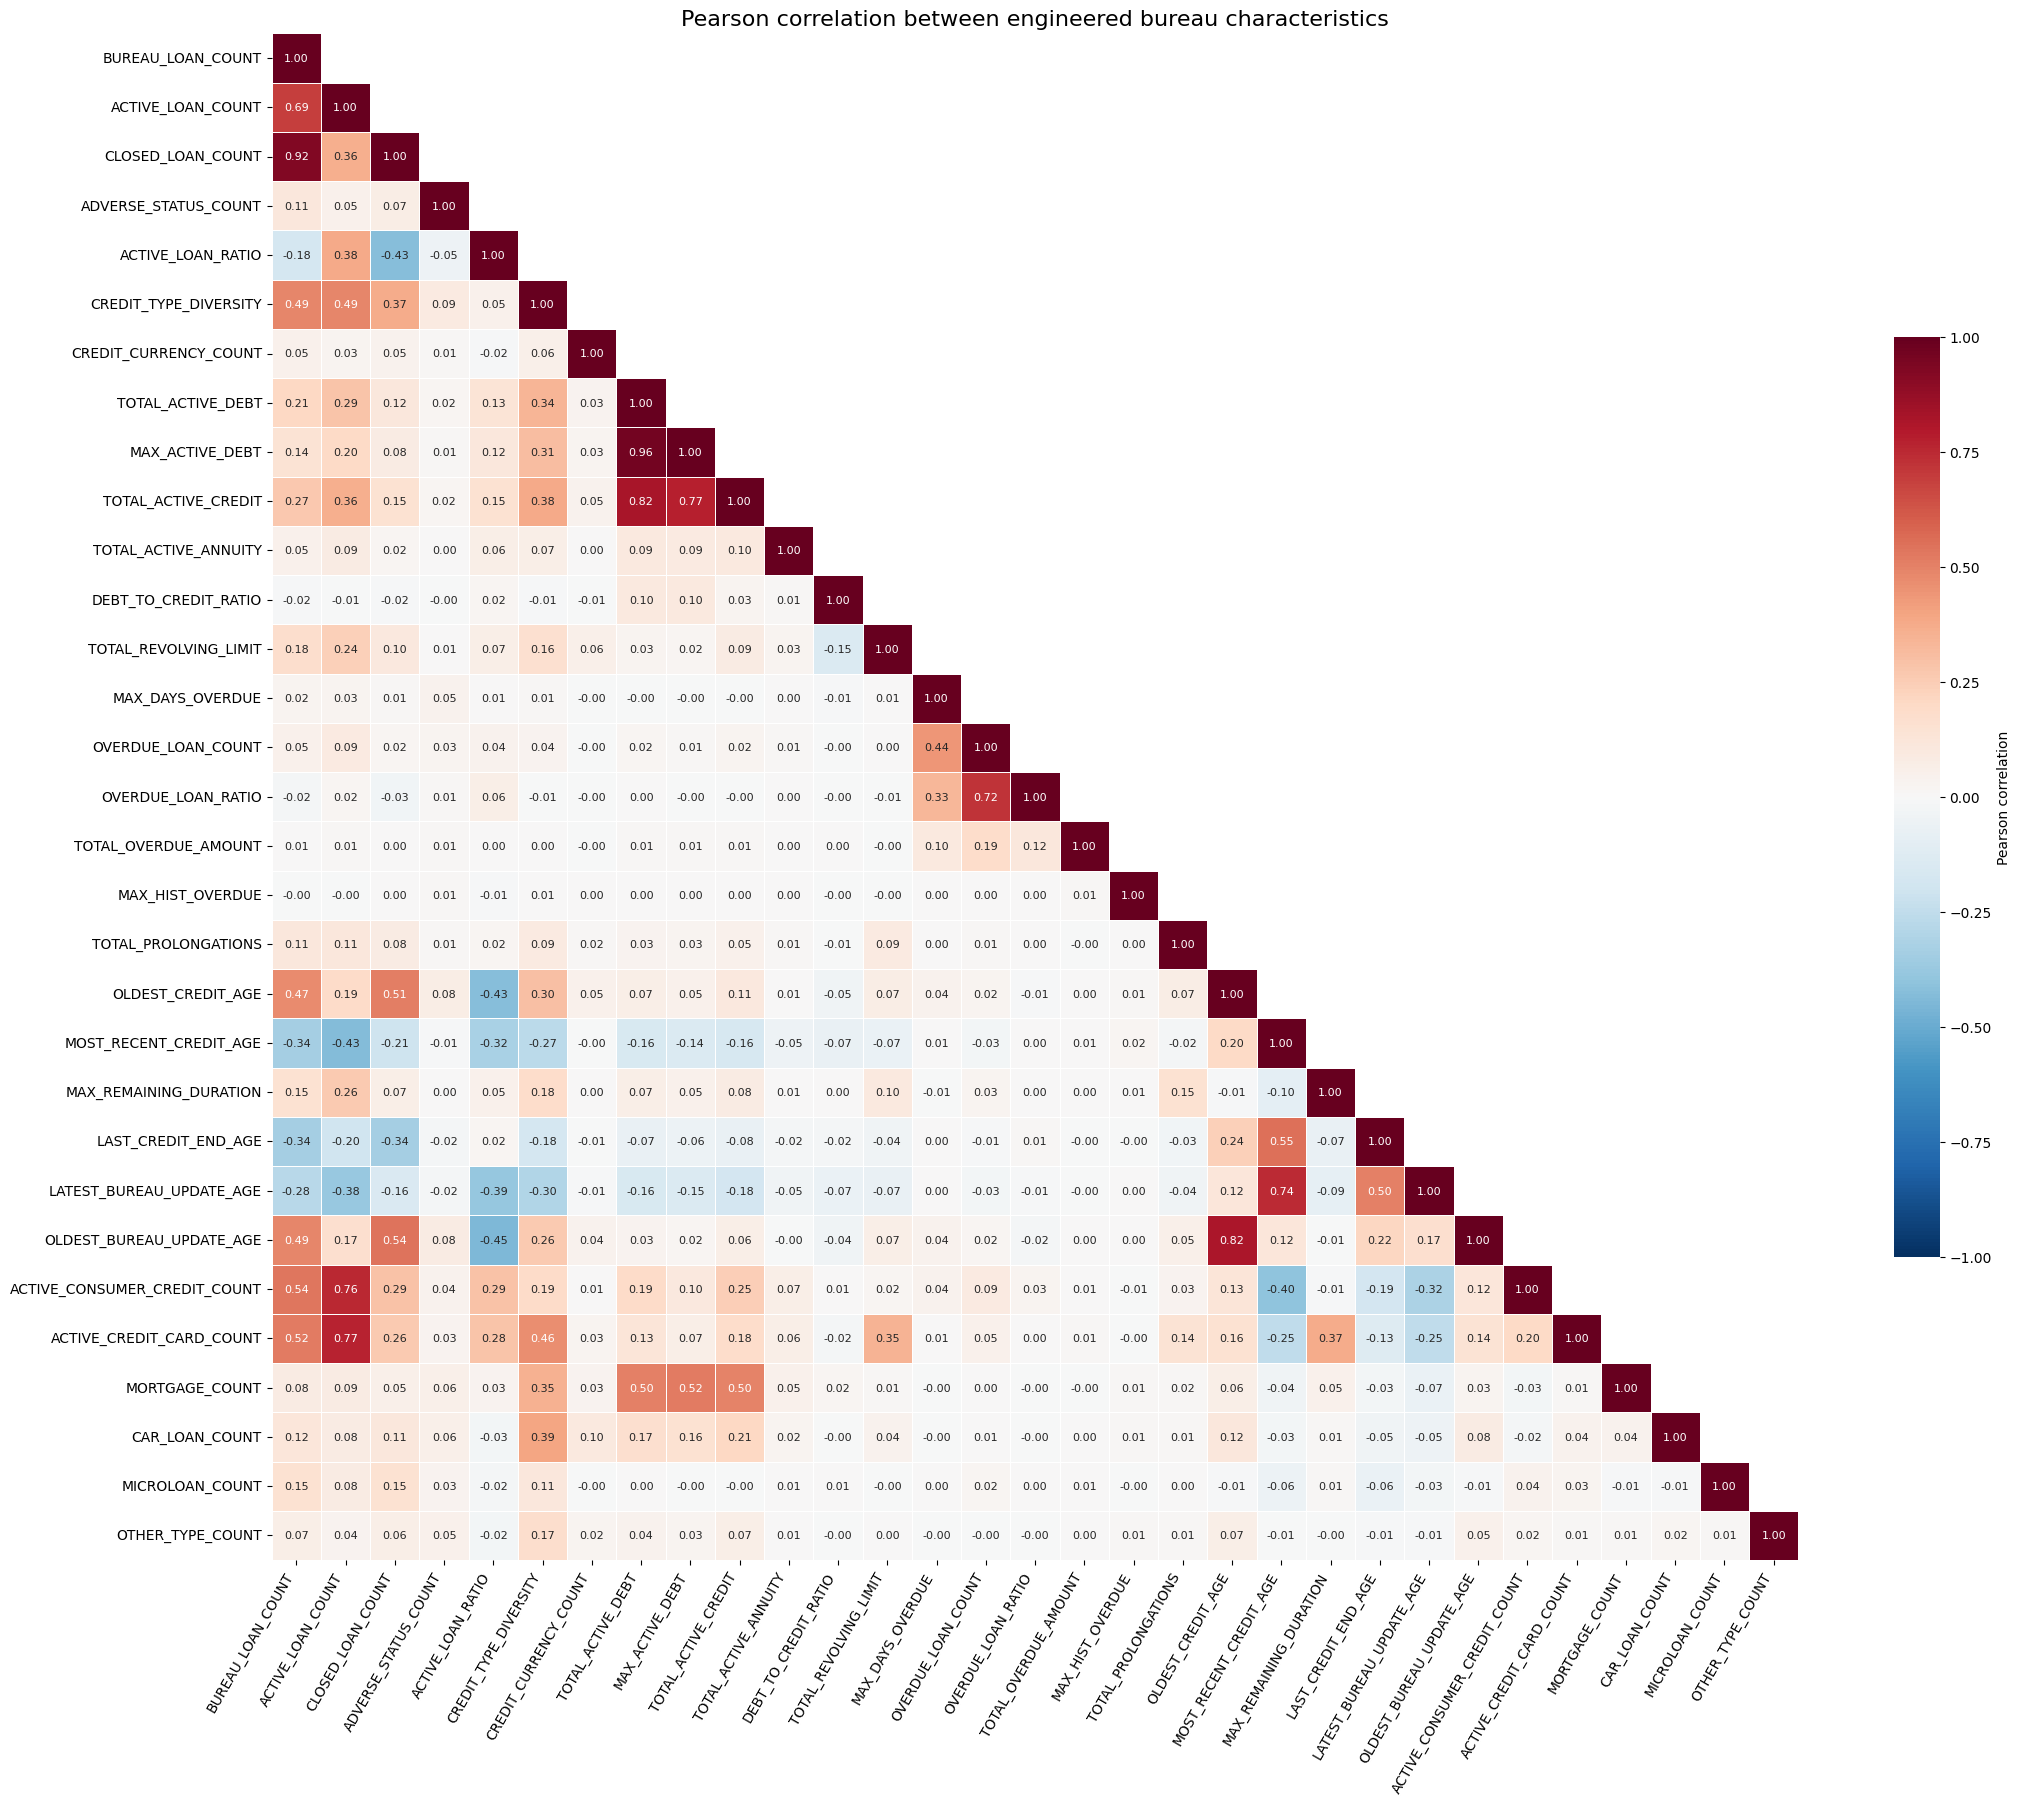

In [29]:
# plot heat map of engineered bureau characteristics
fig, ax = plt.subplots(figsize=(22, 18))
mask = np.triu(np.ones_like(cor, dtype=bool), k=1)
sns.heatmap(cor, mask=mask, annot=True, fmt='.2f', annot_kws={'size': 8},
            cmap='RdBu_r', vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.6, 'label': 'Pearson correlation'}, ax=ax)
ax.set_title('Pearson correlation between engineered bureau characteristics', fontsize=16)
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

### C. Highly correlated feature pairs (|r| ≥ 0.70)

In [30]:
# use cor.unstack() on the upper triangle to get unique pairs without self-correlations
upper = cor.where(np.triu(np.ones(cor.shape, dtype=bool), k=1))
pairs = upper.unstack().dropna()
high_corr = pairs[pairs.abs() >= 0.70]

# interpretation and recommended action for each flagged pair
pair_notes = {
    ('MAX_ACTIVE_DEBT', 'TOTAL_ACTIVE_DEBT'): (
        'Most active debt sits in one account, so the largest balance tracks the total.',
        'Keep TOTAL_ACTIVE_DEBT; drop MAX_ACTIVE_DEBT'),
    ('CLOSED_LOAN_COUNT', 'BUREAU_LOAN_COUNT'): (
        'Most accounts are closed; CLOSED = TOTAL - ACTIVE - ADVERSE, so it is mechanically derived.',
        'Keep BUREAU_LOAN_COUNT; drop CLOSED_LOAN_COUNT'),
    ('TOTAL_ACTIVE_DEBT', 'TOTAL_ACTIVE_CREDIT'): (
        'Debt is a portion of the same active credit amounts; larger facilities carry larger balances.',
        'Combine: keep TOTAL_ACTIVE_DEBT + DEBT_TO_CREDIT_RATIO'),
    ('OLDEST_BUREAU_UPDATE_AGE', 'OLDEST_CREDIT_AGE'): (
        'The stalest update usually belongs to the oldest (long-closed) account.',
        'Keep OLDEST_CREDIT_AGE; drop OLDEST_BUREAU_UPDATE_AGE'),
    ('MAX_ACTIVE_DEBT', 'TOTAL_ACTIVE_CREDIT'): (
        'Indirect: both track TOTAL_ACTIVE_DEBT.',
        'Resolved by the two decisions above'),
    ('ACTIVE_CREDIT_CARD_COUNT', 'ACTIVE_LOAN_COUNT'): (
        'Credit cards are a large share of active accounts (part-of-whole).',
        'Review: revolving vs total activity may carry different risk'),
    ('ACTIVE_CONSUMER_CREDIT_COUNT', 'ACTIVE_LOAN_COUNT'): (
        'Consumer credit is the other large share of active accounts (part-of-whole).',
        'Review: instalment vs total activity may carry different risk'),
    ('LATEST_BUREAU_UPDATE_AGE', 'MOST_RECENT_CREDIT_AGE'): (
        'A newly opened credit is usually also the most recently updated; Spearman is much lower, so the link is driven by a subset.',
        'Review: borrowing recency and data freshness are different concepts'),
    ('OVERDUE_LOAN_RATIO', 'OVERDUE_LOAN_COUNT'): (
        'Both are zero for almost everyone; ratio = count / total, so ranks are nearly identical.',
        'Keep OVERDUE_LOAN_COUNT; drop OVERDUE_LOAN_RATIO'),
}

def note_for(a, b, i):
    return pair_notes.get((a, b), pair_notes.get((b, a), ('Not pre-assessed', 'Review')))[i]

high_corr_table = pd.DataFrame({
    'Feature A': [a for a, b in high_corr.index],
    'Feature B': [b for a, b in high_corr.index],
    'Pearson correlation': high_corr.values,
    'Spearman correlation': [cor_spearman.loc[a, b] for a, b in high_corr.index],
})
high_corr_table['Absolute correlation'] = high_corr_table['Pearson correlation'].abs()
high_corr_table['Interpretation'] = [note_for(a, b, 0) for a, b in high_corr.index]
high_corr_table['Recommended action'] = [note_for(a, b, 1) for a, b in high_corr.index]
high_corr_table = high_corr_table.sort_values('Absolute correlation', ascending=False).reset_index(drop=True)
high_corr_table.index = high_corr_table.index + 1

print(f'Highly correlated pairs (|r| >= 0.70): {len(high_corr_table)}')
with pd.option_context('display.max_colwidth', None):
    display(high_corr_table.style.format({'Pearson correlation': '{:.3f}', 'Spearman correlation': '{:.3f}', 'Absolute correlation': '{:.3f}'}))

Highly correlated pairs (|r| >= 0.70): 9


,Feature A,Feature B,Pearson correlation,Spearman correlation,Absolute correlation,Interpretation,Recommended action
1,MAX_ACTIVE_DEBT,TOTAL_ACTIVE_DEBT,0.961,0.989,0.961,"Most active debt sits in one account, so the largest balance tracks the total.",Keep TOTAL_ACTIVE_DEBT; drop MAX_ACTIVE_DEBT
2,CLOSED_LOAN_COUNT,BUREAU_LOAN_COUNT,0.924,0.885,0.924,"Most accounts are closed; CLOSED = TOTAL - ACTIVE - ADVERSE, so it is mechanically derived.",Keep BUREAU_LOAN_COUNT; drop CLOSED_LOAN_COUNT
3,TOTAL_ACTIVE_CREDIT,TOTAL_ACTIVE_DEBT,0.824,0.885,0.824,Debt is a portion of the same active credit amounts; larger facilities carry larger balances.,Combine: keep TOTAL_ACTIVE_DEBT + DEBT_TO_CREDIT_RATIO
4,OLDEST_BUREAU_UPDATE_AGE,OLDEST_CREDIT_AGE,0.817,0.820,0.817,The stalest update usually belongs to the oldest (long-closed) account.,Keep OLDEST_CREDIT_AGE; drop OLDEST_BUREAU_UPDATE_AGE
5,TOTAL_ACTIVE_CREDIT,MAX_ACTIVE_DEBT,0.774,0.871,0.774,Indirect: both track TOTAL_ACTIVE_DEBT.,Resolved by the two decisions above
6,ACTIVE_CREDIT_CARD_COUNT,ACTIVE_LOAN_COUNT,0.770,0.728,0.770,Credit cards are a large share of active accounts (part-of-whole).,Review: revolving vs total activity may carry different risk
7,ACTIVE_CONSUMER_CREDIT_COUNT,ACTIVE_LOAN_COUNT,0.757,0.744,0.757,Consumer credit is the other large share of active accounts (part-of-whole).,Review: instalment vs total activity may carry different risk
8,LATEST_BUREAU_UPDATE_AGE,MOST_RECENT_CREDIT_AGE,0.743,0.508,0.743,"A newly opened credit is usually also the most recently updated; Spearman is much lower, so the link is driven by a subset.",Review: borrowing recency and data freshness are different concepts
9,OVERDUE_LOAN_RATIO,OVERDUE_LOAN_COUNT,0.722,1.000,0.722,"Both are zero for almost everyone; ratio = count / total, so ranks are nearly identical.",Keep OVERDUE_LOAN_COUNT; drop OVERDUE_LOAN_RATIO


**Commentary**

High correlation means **potential redundancy**: the two characteristics move together across applicants, so including both may add little and can destabilise logistic regression coefficients. It does **not** mean either characteristic is useless. Each pair was assessed on:

1. **Business meaning:** same risk dimension? e.g. `CLOSED_LOAN_COUNT` is fully determined by total, active and adverse counts; `OVERDUE_LOAN_RATIO` is the count divided by the total.
2. **Missingness / coverage:** among debt measures, `TOTAL_ACTIVE_DEBT` and `MAX_ACTIVE_DEBT` have the same coverage, so the more interpretable total is kept.
3. **Interpretability:** totals and counts are easier to explain to credit management than maxima of balances or update ages.
4. **Stability:** `OVERDUE_LOAN_RATIO` is non-zero for about 1% of applicants and adds no ranking information beyond the count (Spearman ≈ 1).
5. **Potential distinct value:** product-level counts (cards vs consumer credit) and recency measures (new borrowing vs bureau freshness) may carry different risk even though they correlate, so they are flagged **REVIEW** rather than dropped.

Decisions were not based on which feature has larger values or higher variance, and `TARGET` was not used.

## 1.7 Recommend Which Characteristics to Keep, Combine or Drop

- **KEEP:** distinct, meaningful characteristic with acceptable data quality.
- **COMBINE:** information is represented more efficiently by a justified engineered measure.
- **DROP:** mechanically redundant, effectively constant, invalid or unusable.
- **REVIEW:** potentially redundant, but cannot be excluded before checking its relationship with default (WOE/IV in a later step).

Missing % and the highest absolute correlation are calculated from the data; the decisions and justifications follow from sections 1.2–1.6.

In [31]:
# decision and justification for every engineered characteristic
decisions = {
    'BUREAU_LOAN_COUNT': ('KEEP', 'Core measure of credit-history depth; complete for all applicants with bureau history.'),
    'ACTIVE_LOAN_COUNT': ('KEEP', 'Number of current obligations; distinct from total history.'),
    'CLOSED_LOAN_COUNT': ('DROP', 'Mechanically equals BUREAU_LOAN_COUNT - ACTIVE_LOAN_COUNT - ADVERSE_STATUS_COUNT and correlates 0.92 with BUREAU_LOAN_COUNT.'),
    'ADVERSE_STATUS_COUNT': ('KEEP', 'Sold / bad-debt accounts are a direct adverse credit signal; low correlation with other features. Rare (about 2% non-zero) but meaningful.'),
    'ACTIVE_LOAN_RATIO': ('KEEP', 'Share of history still open; scale-free complement to the counts, moderate correlation only.'),
    'CREDIT_TYPE_DIVERSITY': ('KEEP', 'Breadth of credit experience; no strong correlation with other features.'),
    'CREDIT_CURRENCY_COUNT': ('DROP', 'Effectively constant: only about 0.3% of applicants have more than one currency.'),
    'ACTIVE_CONSUMER_CREDIT_COUNT': ('REVIEW', 'Part of ACTIVE_LOAN_COUNT (r = 0.76), but instalment credit may carry different risk from revolving credit.'),
    'ACTIVE_CREDIT_CARD_COUNT': ('REVIEW', 'Part of ACTIVE_LOAN_COUNT (r = 0.77), but revolving usage may carry different risk; decide after IV.'),
    'MORTGAGE_COUNT': ('KEEP', 'Existing housing debt is directly relevant to homeowners borrowing for home improvement.'),
    'CAR_LOAN_COUNT': ('KEEP', 'Distinct secured-credit experience; low correlation with other features.'),
    'MICROLOAN_COUNT': ('KEEP', 'Short-term high-cost borrowing can signal financial stress; low correlation with other features.'),
    'OTHER_TYPE_COUNT': ('DROP', 'Heterogeneous mix of rare credit types (about 1% non-zero) with no single interpretation; breadth already captured by CREDIT_TYPE_DIVERSITY.'),
    'TOTAL_ACTIVE_DEBT': ('KEEP', 'Primary measure of outstanding liabilities and affordability.'),
    'MAX_ACTIVE_DEBT': ('DROP', 'Correlates 0.96 with TOTAL_ACTIVE_DEBT with the same coverage; the total is the more meaningful exposure measure.'),
    'TOTAL_ACTIVE_CREDIT': ('COMBINE', 'Correlates 0.82 with TOTAL_ACTIVE_DEBT; its information is represented by DEBT_TO_CREDIT_RATIO alongside TOTAL_ACTIVE_DEBT.'),
    'TOTAL_ACTIVE_ANNUITY': ('DROP', 'Unusable coverage: missing for about 59% of applicants because AMT_ANNUITY is mostly unreported.'),
    'DEBT_TO_CREDIT_RATIO': ('KEEP', 'Combined measure replacing TOTAL_ACTIVE_CREDIT: share of active credit still owed. Missing when there is no active credit.'),
    'TOTAL_REVOLVING_LIMIT': ('KEEP', 'Available revolving credit (credit cards only, per data dictionary); low correlation with other features.'),
    'MAX_DAYS_OVERDUE': ('KEEP', 'Severity of current delinquency.'),
    'OVERDUE_LOAN_COUNT': ('KEEP', 'Frequency of current delinquency; easier to explain than the ratio.'),
    'OVERDUE_LOAN_RATIO': ('DROP', 'Count / total; non-zero for about 1% of applicants and rank-identical to OVERDUE_LOAN_COUNT (Spearman = 1.00).'),
    'TOTAL_OVERDUE_AMOUNT': ('KEEP', 'Magnitude of current overdue exposure.'),
    'MAX_HIST_OVERDUE': ('KEEP', 'Worst historical overdue amount; distinct from current overdue. About 30% missing, which can be kept as its own bin later.'),
    'TOTAL_PROLONGATIONS': ('KEEP', 'Credit extensions requested; distinct repayment-strain signal.'),
    'OLDEST_CREDIT_AGE': ('KEEP', 'Length of credit history; complete coverage.'),
    'MOST_RECENT_CREDIT_AGE': ('REVIEW', 'Correlates 0.74 with LATEST_BUREAU_UPDATE_AGE (Spearman only 0.51); recent new borrowing is a distinct concept.'),
    'MAX_REMAINING_DURATION': ('KEEP', 'Length of remaining commitments; missing only when there are no active accounts.'),
    'LAST_CREDIT_END_AGE': ('KEEP', 'Recency of completed repayment; missing only when there are no closed accounts.'),
    'LATEST_BUREAU_UPDATE_AGE': ('REVIEW', 'Correlates 0.74 with MOST_RECENT_CREDIT_AGE; bureau freshness may matter separately.'),
    'OLDEST_BUREAU_UPDATE_AGE': ('DROP', 'Correlates 0.82 with OLDEST_CREDIT_AGE and mainly reflects old closed accounts; credit age is more interpretable.'),
}

# make sure every engineered characteristic has a decision
assert set(decisions) == set(engineered_cols), set(engineered_cols) ^ set(decisions)

max_abs_corr = cor.where(~np.eye(len(cor), dtype=bool)).abs()
decision_table = pd.DataFrame({
    'Characteristic': engineered_cols,
    'Missing %': [bureau_flat[c].isnull().mean() * 100 for c in engineered_cols],
    'Zero %': [(bureau_flat[c] == 0).mean() * 100 for c in engineered_cols],
    'Highest |corr|': [max_abs_corr[c].max() for c in engineered_cols],
    'Most correlated with': [max_abs_corr[c].idxmax() for c in engineered_cols],
    'Proposed decision': [decisions[c][0] for c in engineered_cols],
    'Justification': [decisions[c][1] for c in engineered_cols],
}).set_index('Characteristic')

with pd.option_context('display.max_colwidth', None):
    display(decision_table.style.format({'Missing %': '{:.2f}', 'Zero %': '{:.2f}', 'Highest |corr|': '{:.3f}'}))

print(decision_table['Proposed decision'].value_counts())

,Missing %,Zero %,Highest |corr|,Most correlated with,Proposed decision,Justification
Characteristic,,,,,,
BUREAU_LOAN_COUNT,0.00,0.00,0.924,CLOSED_LOAN_COUNT,KEEP,Core measure of credit-history depth; complete for all applicants with bureau history.
ACTIVE_LOAN_COUNT,0.00,17.76,0.770,ACTIVE_CREDIT_CARD_COUNT,KEEP,Number of current obligations; distinct from total history.
CLOSED_LOAN_COUNT,0.00,12.58,0.924,BUREAU_LOAN_COUNT,DROP,Mechanically equals BUREAU_LOAN_COUNT - ACTIVE_LOAN_COUNT - ADVERSE_STATUS_COUNT and correlates 0.92 with BUREAU_LOAN_COUNT.
ADVERSE_STATUS_COUNT,0.00,98.02,0.114,BUREAU_LOAN_COUNT,KEEP,Sold / bad-debt accounts are a direct adverse credit signal; low correlation with other features. Rare (about 2% non-zero) but meaningful.
ACTIVE_LOAN_RATIO,0.00,17.76,0.453,OLDEST_BUREAU_UPDATE_AGE,KEEP,"Share of history still open; scale-free complement to the counts, moderate correlation only."
CREDIT_TYPE_DIVERSITY,0.00,0.00,0.491,BUREAU_LOAN_COUNT,KEEP,Breadth of credit experience; no strong correlation with other features.
CREDIT_CURRENCY_COUNT,0.00,0.00,0.096,CAR_LOAN_COUNT,DROP,Effectively constant: only about 0.3% of applicants have more than one currency.
TOTAL_ACTIVE_DEBT,4.02,26.34,0.961,MAX_ACTIVE_DEBT,KEEP,Primary measure of outstanding liabilities and affordability.
MAX_ACTIVE_DEBT,4.02,26.34,0.961,TOTAL_ACTIVE_DEBT,DROP,Correlates 0.96 with TOTAL_ACTIVE_DEBT with the same coverage; the total is the more meaningful exposure measure.


Proposed decision
KEEP       19
DROP        7
REVIEW      4
COMBINE     1
Name: count, dtype: int64


**Notes on the decisions**

- Correlation above 0.70 did not trigger an automatic drop. Pairs with different business meaning (product counts vs total active count, borrowing recency vs bureau freshness) are kept as **REVIEW** so WOE/IV can decide later.
- The only **COMBINE** decision is `TOTAL_ACTIVE_CREDIT`, represented by `DEBT_TO_CREDIT_RATIO` + `TOTAL_ACTIVE_DEBT`. The raw amount and ratio are not both kept.
- Each **DROP** is mechanically redundant (`CLOSED_LOAN_COUNT`, `OVERDUE_LOAN_RATIO`), dominated by a near-duplicate (`MAX_ACTIVE_DEBT`, `OLDEST_BUREAU_UPDATE_AGE`), effectively constant (`CREDIT_CURRENCY_COUNT`), uninterpretable (`OTHER_TYPE_COUNT`) or too sparse (`TOTAL_ACTIVE_ANNUITY`).
- Dropped characteristics remain in the full export below, so they can be recovered.

## 1.8 Export Merge-Ready Bureau Dataset

Two files are saved:

1. `01_Bureau_Features_Full.csv` – all engineered characteristics before redundancy reduction.
2. `01_flattened_Bureau_data.csv` – `SK_ID_CURR` plus KEEP and REVIEW characteristics (including the COMBINE replacement `DEBT_TO_CREDIT_RATIO`).

Neither file contains `SK_ID_BUREAU`, raw bureau rows, `TARGET` or application characteristics.

In [32]:
# select characteristics for the reduced dataset
keep_cols = decision_table[decision_table['Proposed decision'].isin(['KEEP', 'REVIEW'])].index.tolist()
removed_cols = decision_table[decision_table['Proposed decision'].isin(['DROP', 'COMBINE'])].index.tolist()

bureau_full = bureau_flat[['SK_ID_CURR'] + engineered_cols].copy()
bureau_reduced = bureau_flat[['SK_ID_CURR'] + keep_cols].copy()

print('Removed (DROP / COMBINE):', removed_cols)

Removed (DROP / COMBINE): ['CLOSED_LOAN_COUNT', 'CREDIT_CURRENCY_COUNT', 'MAX_ACTIVE_DEBT', 'TOTAL_ACTIVE_CREDIT', 'TOTAL_ACTIVE_ANNUITY', 'OVERDUE_LOAN_RATIO', 'OLDEST_BUREAU_UPDATE_AGE', 'OTHER_TYPE_COUNT']


In [33]:
# export validation
checks = {
    '1. No duplicate SK_ID_CURR': bureau_reduced['SK_ID_CURR'].is_unique,
    '2. Column names unique': bureau_reduced.columns.is_unique and bureau_full.columns.is_unique,
    '3. All characteristics numeric': all(pd.api.types.is_numeric_dtype(bureau_reduced[c]) for c in keep_cols),
    '4. No infinite values': not np.isinf(bureau_reduced[keep_cols]).any().any(),
    '6a. No constant columns': (bureau_reduced[keep_cols].nunique() > 1).all(),
    '6b. No duplicate columns': not bureau_reduced[keep_cols].T.duplicated().any(),
    '7. One-to-one merge on SK_ID_CURR possible': bureau_reduced['SK_ID_CURR'].is_unique and segment_ids.is_unique,
    'No SK_ID_BUREAU / TARGET': not {'SK_ID_BUREAU', 'TARGET'} & set(bureau_reduced.columns),
}
for name, result in checks.items():
    print(f'{name}: {result}')
assert all(checks.values())

# 5. missingness after aggregation
print('\n5. Missing % in reduced dataset:')
print((bureau_reduced[keep_cols].isnull().mean() * 100).round(2).sort_values(ascending=False).to_string())

1. No duplicate SK_ID_CURR: True
2. Column names unique: True
3. All characteristics numeric: True
4. No infinite values: True
6a. No constant columns: True
6b. No duplicate columns: True
7. One-to-one merge on SK_ID_CURR possible: True
No SK_ID_BUREAU / TARGET: True

5. Missing % in reduced dataset:
MAX_HIST_OVERDUE               30.3500
DEBT_TO_CREDIT_RATIO           22.9300
MAX_REMAINING_DURATION         21.1100
LAST_CREDIT_END_AGE            12.5900
TOTAL_REVOLVING_LIMIT           8.2000
TOTAL_ACTIVE_DEBT               4.0200
TOTAL_OVERDUE_AMOUNT            0.0100
ACTIVE_LOAN_RATIO               0.0000
CREDIT_TYPE_DIVERSITY           0.0000
ACTIVE_LOAN_COUNT               0.0000
ADVERSE_STATUS_COUNT            0.0000
BUREAU_LOAN_COUNT               0.0000
TOTAL_PROLONGATIONS             0.0000
OVERDUE_LOAN_COUNT              0.0000
MAX_DAYS_OVERDUE                0.0000
MOST_RECENT_CREDIT_AGE          0.0000
OLDEST_CREDIT_AGE               0.0000
LATEST_BUREAU_UPDATE_AGE        0.0

In [34]:
# save both outputs
bureau_full.to_csv('data/01_Bureau_Features_Full.csv', index=False)
bureau_reduced.to_csv('data/01_flattened_Bureau_data.csv', index=False)

# 8. final rows and characteristics
print(f'01_Bureau_Features_Full.csv:   {bureau_full.shape[0]:,} rows, {bureau_full.shape[1] - 1} characteristics + SK_ID_CURR')
print(f'01_flattened_Bureau_data.csv:  {bureau_reduced.shape[0]:,} rows, {bureau_reduced.shape[1] - 1} characteristics + SK_ID_CURR')

01_Bureau_Features_Full.csv:   181,841 rows, 31 characteristics + SK_ID_CURR
01_flattened_Bureau_data.csv:  181,841 rows, 23 characteristics + SK_ID_CURR


## 1.9 Final Summary and Business Interpretation

In [35]:
# summary of the flattening and reduction process
raw_chars = [c for c in bureau_data_orig.columns if c not in ['SK_ID_CURR', 'SK_ID_BUREAU']]

summary = pd.DataFrame({'Result': [
    f'{len(bureau_data_orig):,}',
    f'{len(bureau_seg):,}',
    f'{len(bureau_clean):,}',
    f'{bureau_reduced["SK_ID_CURR"].nunique():,}',
    f'{(~segment_ids.isin(bureau_reduced["SK_ID_CURR"])).sum():,}',
    len(raw_chars),
    len(engineered_cols),
    len(high_corr_table),
    f"{len(removed_cols)} ({(decision_table['Proposed decision'] == 'DROP').sum()} dropped, {(decision_table['Proposed decision'] == 'COMBINE').sum()} combined)",
    f"{len(keep_cols)} ({(decision_table['Proposed decision'] == 'KEEP').sum()} KEEP, {(decision_table['Proposed decision'] == 'REVIEW').sum()} REVIEW)",
]}, index=[
    'Original bureau rows',
    'Relevant bureau rows after applicant filtering',
    'Bureau rows after data-quality treatment',
    'Unique eligible applicants with bureau history',
    'Eligible applicants without bureau history',
    'Raw bureau characteristics (excl. IDs)',
    'Engineered bureau characteristics',
    'Highly correlated feature pairs (|r| >= 0.70)',
    'Characteristics dropped or combined',
    'Final merge-ready bureau characteristics',
])
summary.index.name = 'Metric'
summary

,Result
Metric,
Original bureau rows,"1,716,428"
Relevant bureau rows after applicant filtering,"1,016,708"
Bureau rows after data-quality treatment,"1,016,697"
Unique eligible applicants with bureau history,"181,841"
Eligible applicants without bureau history,"31,471"
Raw bureau characteristics (excl. IDs),15
Engineered bureau characteristics,31
Highly correlated feature pairs (|r| >= 0.70),9
Characteristics dropped or combined,"8 (7 dropped, 1 combined)"


**Why flatten?** Applicants have a median of 4 and up to 94 bureau records, while the scorecard needs one row per applicant. Aggregating by `SK_ID_CURR` turns many credit lines into a single applicant-level credit profile that can be left-merged onto the Step 0 segment.

**How the aggregations preserve risk information**

- Counts by status and product describe the depth and mix of credit, keeping *Sold/Bad debt* as a separate adverse signal.
- Exposure uses active accounts in one currency, so totals represent what the applicant currently owes in comparable units. `DEBT_TO_CREDIT_RATIO` adds a utilisation view.
- Delinquency keeps severity (max days), frequency (count) and magnitude (current and historical amounts) separate.
- Day variables are converted to years with signs that read naturally, keeping their meaning (e.g. remaining duration can be negative for overdue active accounts).

**Redundancy found:** 9 pairs with |r| ≥ 0.70. They fall into four patterns: (1) mechanical identities (closed count, overdue ratio), (2) total vs largest/related amounts (active debt vs max debt and credit), (3) part-of-whole product counts, and (4) related time measures (credit age vs bureau update age).

**Why the final characteristics were kept:** 23 characteristics remain, each covering a distinct dimension of history, exposure, delinquency or recency with acceptable data quality. Four correlated characteristics (`ACTIVE_CONSUMER_CREDIT_COUNT`, `ACTIVE_CREDIT_CARD_COUNT`, `MOST_RECENT_CREDIT_AGE`, `LATEST_BUREAU_UPDATE_AGE`) are kept as **REVIEW** because their business meaning differs from their correlated partner. Their predictive value will be judged with WOE/IV against `TARGET` in a later step, not removed now.

**Limitations**

- **Coverage:** 31,471 eligible applicants (about 15% of the segment) have no bureau records. A missing bureau history is not evidence of low risk; these applicants must be kept in the left merge and handled as a separate (missing) group.
- **Missing data:** `MAX_HIST_OVERDUE` (about 30% missing), `DEBT_TO_CREDIT_RATIO` (about 23%), `MAX_REMAINING_DURATION` (about 21%) and `LAST_CREDIT_END_AGE` (about 13%) have structural or reporting gaps, and missing values were not converted to zero.
- **Currencies:** monetary features exclude the 824 non-currency-1 records (640 applicants) because no exchange rates exist, so their exposure is slightly understated.
- **Unusual values:** long remaining durations, debt above the credit amount, very large debt and overdue amounts, and a small number of corrected dates/amounts remain. They are documented, not capped, and will be handled through coarse classing.
- **Rare events:** delinquency features are zero for about 97–99% of applicants, so their bins will be small and need careful grouping.